# 02 · Analysis

Block 2 check: image metrics, the quadratic search (z / C1 / A1) and particle segmentation.

Sections 1–5 need **no microscope**: the digital twin's image does not change with z, C1 or A1, so the search runs on **synthetic images** blurred by the distance to a hidden optimum (`SyntheticScope`). Section 6 segments a live overview (twin or real).

In [1]:
TARGET = "twin"   # section 6 only: "twin" or "real"

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np

from stem_agent.analysis.metrics import METRICS
from stem_agent.analysis.optimizer import QuadraticSearch
from stem_agent.analysis.segmentation import segment
from stem_agent.analysis.synthetic import SyntheticScope, blur, particle_image
from stem_agent.utils.plots import plot_particles, plot_search


def run(search, scope):
    """The ask / tell loop a tuning node will run, with the synthetic scope as the microscope."""
    while (offset := search.ask()) is not None:
        search.tell(offset, scope.score(offset))
    return search

## 1 · Metrics vs blur
Each metric relative to its value on the sharp image, without and with noise. A metric the search can **maximize** must fall steadily with blur.

Expected: `contrast` and `edge_sharpness` fall steadily; `entropy` **rises** with blur (maximizing it defocuses); `high_frequency_power` falls near focus but rises again further out and with noise.

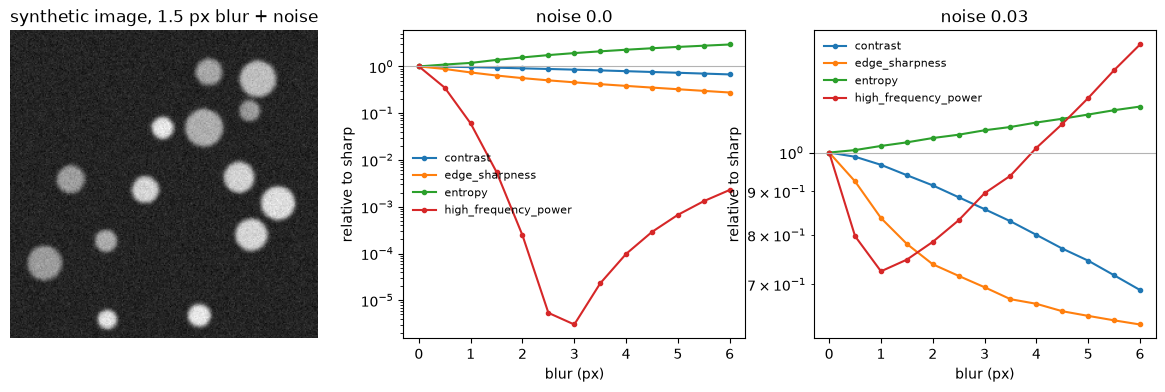

In [3]:
sharp, _ = particle_image(size=256, seed=3)
blurs = np.linspace(0, 6, 13)
rng = np.random.default_rng(0)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(blur(sharp, defocus_px=1.5, noise=0.03, rng=rng), cmap="gray")
axes[0].set_title("synthetic image, 1.5 px blur + noise")
axes[0].axis("off")
for ax, noise in zip(axes[1:], (0.0, 0.03)):
    for name, fn in METRICS.items():
        values = np.array([fn(blur(sharp, defocus_px=b, noise=noise, rng=rng)) for b in blurs])
        ax.plot(blurs, values / values[0], "o-", ms=3, label=name)
    ax.axhline(1, color="0.7", lw=0.8)
    ax.set(xlabel="blur (px)", ylabel="relative to sharp", title=f"noise {noise}", yscale="log")
    ax.legend(frameon=False, fontsize=8)
plt.show()

## 2 · 1D search (stage z)
Hidden optimum at +3.3 µm; blur grows 0.5 px per µm away from it. Notebook settings: step 1 µm, max offset 20 µm, 8 model iterations, metric `contrast`.

Expected: the best point within about step/8 of the optimum.

best +3.486 um (truth +3.300) | 11 measurements | stop: max_iterations


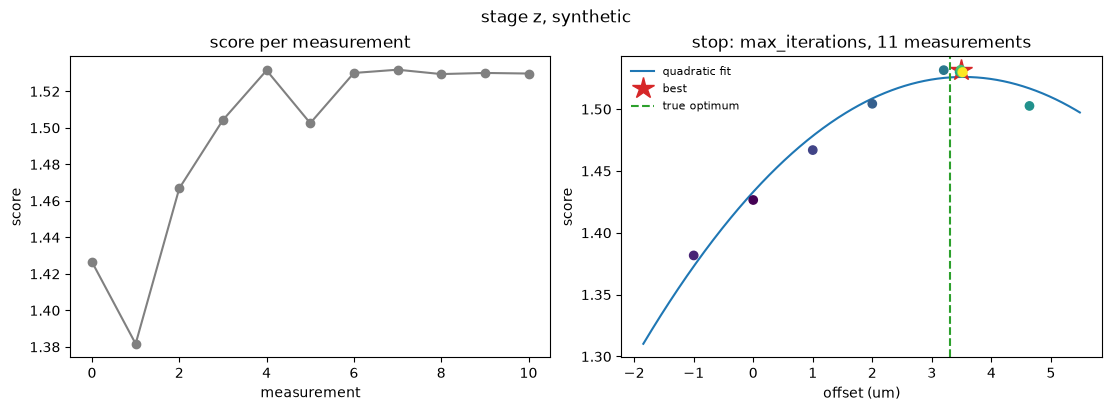

In [4]:
scope = SyntheticScope(1, optimum_m=3.3e-6, px_per_m=0.5e6, metric="contrast", noise=0.01)
search = run(QuadraticSearch(1, step=1e-6, max_offset=20e-6, max_iterations=8), scope)
best = search.best()
print(f"best {best.offset[0] * 1e6:+.3f} um (truth +3.300) | {len(search.history)} measurements | stop: {search.stop_reason}")
plot_search(search, "stage z, synthetic", unit=1e-6, unit_name="um", truth=scope.optimum)

## 3 · 2D search (A1)
Hidden astigmatism optimum at (1.0, −0.6) nm; 1 px of stretched blur per nm away from it. Notebook settings: step 2 nm, 8 points on a circle, 8 model iterations.

Expected: the best point near the optimum (the 2D search has fewer points per dimension, so it is less exact than 1D).

best (+1.06, -0.61) nm (truth +1.00, -0.60) | 17 measurements | stop: converged


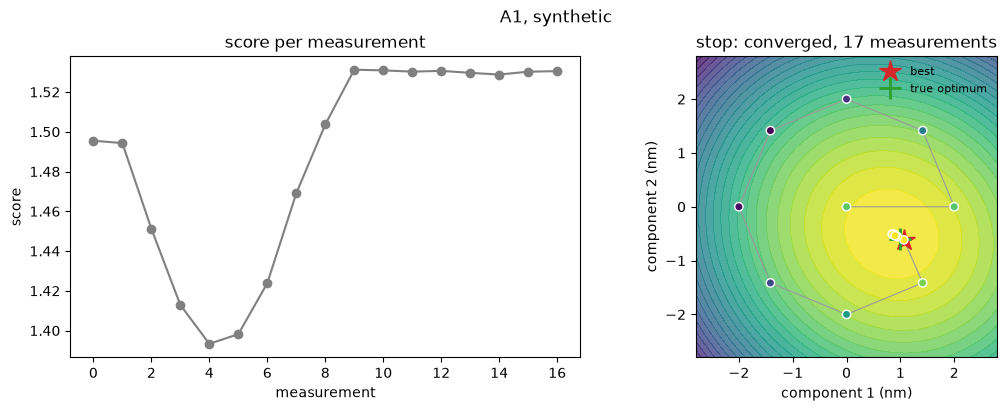

In [5]:
scope_a1 = SyntheticScope(2, optimum_m=(1.0e-9, -0.6e-9), px_per_m=1e9, metric="contrast", noise=0.01)
search_a1 = run(QuadraticSearch(2, step=2e-9, max_iterations=8), scope_a1)
best = search_a1.best()
print(f"best ({best.offset[0] * 1e9:+.2f}, {best.offset[1] * 1e9:+.2f}) nm (truth +1.00, -0.60) | "
      f"{len(search_a1.history)} measurements | stop: {search_a1.stop_reason}")
plot_search(search_a1, "A1, synthetic", unit=1e-9, unit_name="nm", truth=scope_a1.optimum)

## 4 · Limit
Hidden optimum at +30 µm, but `max_offset` is 10 µm. Expected: no point ever beyond 10 µm; the search ends at the edge.

furthest point 10.000 um (limit 10) | best +9.992 um


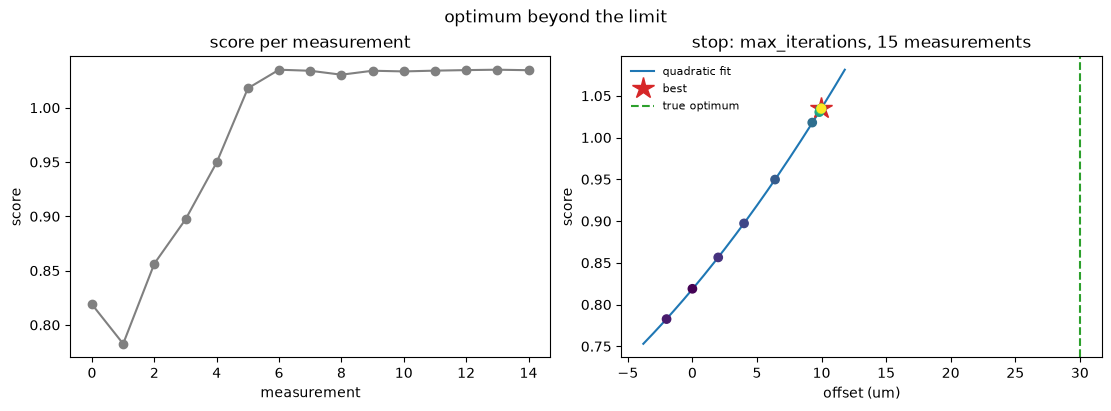

In [6]:
scope_far = SyntheticScope(1, optimum_m=30e-6, px_per_m=0.3e6, noise=0.01)
search_far = run(QuadraticSearch(1, step=2e-6, max_offset=10e-6, max_iterations=12), scope_far)
furthest = max(abs(p.offset[0]) for p in search_far.history)
print(f"furthest point {furthest * 1e6:.3f} um (limit 10) | best {search_far.best().offset[0] * 1e6:+.3f} um")
plot_search(search_far, "optimum beyond the limit", unit=1e-6, unit_name="um", truth=scope_far.optimum)

## 5 · Which metric, how much noise
The 1D search with each metric and three noise levels, 6 random optima each (within ±8 µm). Table: median distance of the best point from the optimum, in steps (1 step = 1 µm). Small is good.

This is the question behind the saved notebook run where z and C1 ended at 0 offset: is the metric sensitive enough?

In [8]:
noises = (0.0, 0.02, 0.05)
print(f"{'metric':<22}" + "".join(f"noise {n:<6}" for n in noises))
for name in METRICS:
    row = []
    for noise in noises:
        errors = []
        for seed in range(6):
            optimum = np.random.default_rng(seed).uniform(-8e-6, 8e-6)
            scope_n = SyntheticScope(1, optimum, px_per_m=0.5e6, metric=name, noise=noise, size=128, seed=seed)
            result = run(QuadraticSearch(1, step=1e-6, max_offset=20e-6), scope_n)
            errors.append(abs(result.best().offset[0] - optimum) / 1e-6)
        row.append(np.median(errors))
    print(f"{name:<22}" + "".join(f"{e:<12.2f}" for e in row))

metric                noise 0.0   noise 0.02  noise 0.05  
contrast              0.25        0.18        0.34        
edge_sharpness        0.25        0.19        0.18        
entropy               13.56       13.40       10.12       
high_frequency_power  18.72       18.72       18.72       


## 6 · Segmentation
Otsu with settings in nm (`smooth_nm`, `min_diameter_nm`), so the same settings work for the twin (128 px) and the real microscope (512 px). Red circles: beam aim points (deepest pixel inside each particle), numbered largest first.

First a synthetic 512 px image with known particles, then a live overview.

**Before the live part (twin):** `uv run python scripts/twin.py start`.

synthetic: 20 particles found, 20 placed (particles touching the edge are dropped)


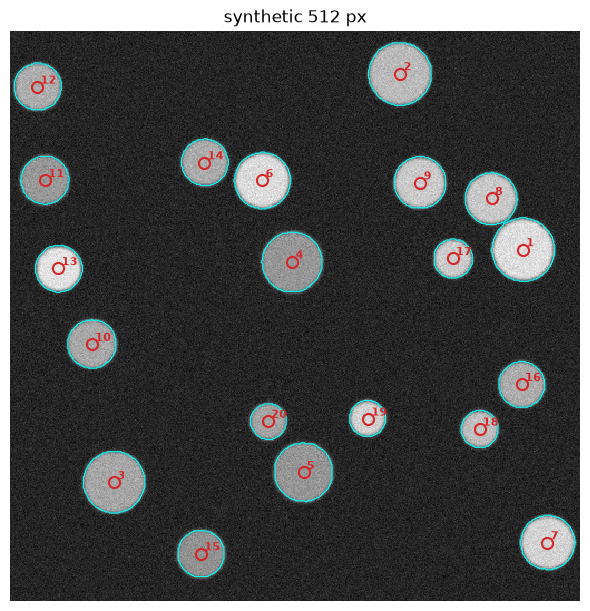

In [9]:
image, disks = particle_image(size=512, n=20, radius_px=(14, 30), seed=5)
image = blur(image, defocus_px=1.5, noise=0.03, rng=np.random.default_rng(1))
labels, particles = segment(image, fov_m=100e-9)
print(f"synthetic: {len(particles)} particles found, {len(disks)} placed "
      f"(particles touching the edge are dropped)")
plot_particles(image, labels, particles, "synthetic 512 px")

twin: FOV 20 nm, image (128, 128), 12 particles
  1: aim (87, 34), centroid (86.6, 34.1), area 446 px
  2: aim (58, 68), centroid (58.1, 67.7), area 373 px
  3: aim (79, 89), centroid (78.9, 88.9), area 331 px
  4: aim (46, 90), centroid (45.9, 89.8), area 298 px
  5: aim (43, 35), centroid (42.9, 35.1), area 294 px


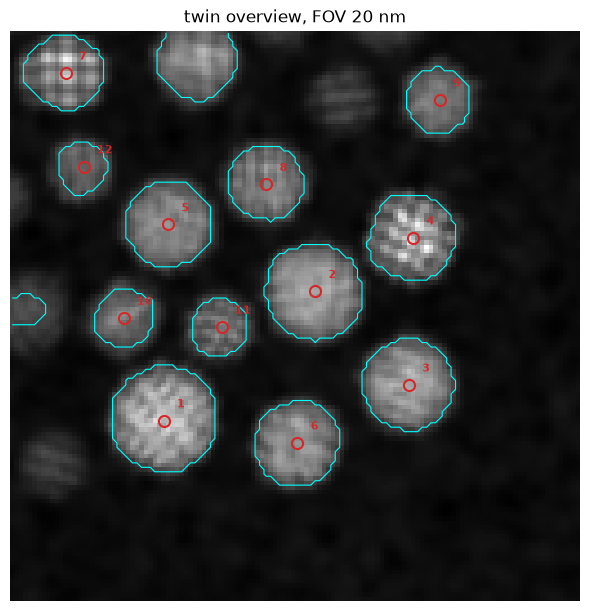

In [10]:
from stem_agent.data import tiled_io
from stem_agent.mcp import session
from stem_agent.nodes import common

session.connect(TARGET)
tiled_io.connect(json.loads(await session.call("get_tiled_config"))["uri"])
fov = await session.call("get_fov")
key, overview = await common.acquire_haadf()
labels, particles = segment(overview, fov_m=fov)
print(f"{TARGET}: FOV {fov * 1e9:.0f} nm, image {overview.shape}, {len(particles)} particles")
for p in particles[:5]:
    print(f"  {p['id']}: aim ({p['row']:.0f}, {p['col']:.0f}), centroid "
          f"({p['centroid'][0]:.1f}, {p['centroid'][1]:.1f}), area {p['area_px']} px")
plot_particles(overview, labels, particles, f"{TARGET} overview, FOV {fov * 1e9:.0f} nm")